# Harmonic oscillator: three linearizations

This example computes the kinetic energy $T=\tfrac12p^{2}$ of one harmonic oscillator over time,
by all three linearizations. The three answers agree with each other and with the closed form.

:::{seealso}
- [Vocabulary and symbols](../../docs/concepts.md) defines site, basis, bra, ket, vacuum,
  generator, observable, the three generators $\mathcal K$, $\mathcal L$, $\mathcal L_{\rm KvN}$
  and the matrix convention $M[\beta,\alpha]$.
- [3. Bases](../tutorials/04_basis/index.ipynb) constructs the three bases.
:::

`lin_ode` rewrites a nonlinear ODE as a linear one, so it can be solved by a matrix exponential:

$$\dot u=f(u)
\quad\longrightarrow\quad
\dot{\boldsymbol\phi}=M^{\mathsf T}\boldsymbol\phi
\quad\longrightarrow\quad
\boldsymbol\phi(t)=e^{M^{\mathsf T}t}\,\boldsymbol\phi(0)$$

$\boldsymbol\phi$ collects basis functions of the state, so a nonlinear term becomes another
coordinate.

With $m=\omega=1$, the equations of motion are

$$\frac{dq}{dt}=p,\qquad\frac{dp}{dt}=-q,\qquad u_0=q,\ u_1=p.$$

`lin_ode` addresses the state by site, so this system is a grid of two sites: $q$ at site 0 and
$p$ at site 1.

The three parts below differ in the initial condition, the generator and the basis.

| | initial condition | generator | basis |
| --- | --- | --- | --- |
| Part 1 | a known point $(q,p)=(1,0)$ | $\mathcal K$ | `CarlemanBasis` |
| Part 2 | a Gaussian density around it | $\mathcal L$, then $\mathcal K$ | `GaussianHermiteBasis` |
| Part 3 | the same density, as an amplitude | $\mathcal L_{\rm KvN}$ | `GaussianHermiteBasis` |

`GaussianHermiteBasis` is square-integrable, so `Liouville` and `KoopmanVonNeumann` accept it.
`CarlemanBasis` is not.

From $(1,0)$ the trajectory is $q=\cos t$, $p=-\sin t$, so $T=\tfrac12\sin^{2}t$.

For a density, $\langle T\rangle=\tfrac12\bigl(\langle p\rangle^{2}+\operatorname{Var}p\bigr)$, and
$\operatorname{Var}p(t)=\operatorname{Var}p(0)$.


## The equations of motion

The two sites carry different dynamics, so the right-hand side is a `Piecewise` keyed on the site
index. `from_sympy` takes it as it stands.

In [1]:
import numpy as np
import sympy as sp
from scipy.integrate import quad
from scipy.linalg import expm
from scipy.special import eval_hermite, factorial

from lin_ode import ObservableExpression, OperatorMatrix, OrdinaryDifferentialSystem
from lin_ode.basis import CarlemanBasis, GaussianHermiteBasis, TruncatedBasisSet
from lin_ode.operators import Koopman, KoopmanVonNeumann, Liouville
from lin_ode.vector import Vector

u, i = sp.IndexedBase("u"), sp.Idx("i", (0, 1))  # u[0] = q, u[1] = p
oscillator = OrdinaryDifferentialSystem.from_sympy(
    sp.Piecewise((u[1], sp.Eq(i, 0)), (-u[0], True)), u, (i,)
)
kinetic_energy = u[1] ** 2 / 2

print("f_i =", oscillator.equation.expr)
print("div f =", sp.diff(u[1], u[0]) + sp.diff(-u[0], u[1]), " <- Hamiltonian flow, incompressible")

times = np.linspace(0, 2 * np.pi, 65)
exact_point = 0.5 * np.sin(times) ** 2  # T(t) from (q, p) = (1, 0)

f_i = Piecewise((u[1], Eq(i, 0)), (-u[0], True))
div f = 0  <- Hamiltonian flow, incompressible


## Part 1: Koopman on a Carleman basis

`Koopman` accepts any basis, so Carleman works here even though a monomial is not square-integrable.

A Carleman basis has $p^{2}$ as one of its monomials, so $T$ is a *row* of the evolved vector.

Degree 2 is enough to hold $p^{2}$. The basis functions then evolve by one matrix exponential,

$$\boldsymbol\phi(u(t))=e^{M^{\mathsf T}t}\,\boldsymbol\phi(u(0))$$

In [2]:
def states_of(basis: TruncatedBasisSet) -> list:
    """Every state of the basis, in flat order."""
    return [basis.structured_idx_of_flat_index(k) for k in range(len(basis))]


def generator(method, basis: TruncatedBasisSet) -> np.ndarray:
    """The dense block of <bra|K|ket> over the whole basis."""
    states = states_of(basis)
    matrix = OperatorMatrix(basis, method.create_operator(oscillator))
    return np.array(matrix[states, states], dtype=float)


carleman = CarlemanBasis(n_vars=2, degree=2)
M_T = generator(Koopman(), carleman).T  # d(phi)/dt = M^T phi

start = (1.0, 0.0)  # (q, p) at t = 0
phi_0 = np.array([float(np.prod([start[int(s)] ** int(n) for s, n in state])) for state in states_of(carleman)])

row_of_p2 = states_of(carleman).index(((1, 2),))  # the state p^2
print(f"{len(carleman)} states: {states_of(carleman)}")
print(f"p^2 is state {row_of_p2}, so T = phi[{row_of_p2}] / 2")

carleman_T = np.array([(expm(M_T * t) @ phi_0)[row_of_p2] / 2 for t in times])
print(f"\nmax |Carleman - exact| = {np.abs(carleman_T - exact_point).max():.2e}")

6 states: [(), ((0, 1),), ((1, 1),), ((0, 2),), ((0, 1), (1, 1)), ((1, 2),)]
p^2 is state 5, so T = phi[5] / 2

max |Carleman - exact| = 2.28e-14


The oscillator is linear, so the generator maps degree-2 monomials among themselves and nothing
goes above the degree. The error is therefore at machine precision.

## Part 2: Liouville and Koopman on a Gauss–Hermite basis

The start is now a Gaussian density of unit variance centred on $(1,0)$.

### The basis must carry an inner product

An expectation value is an integral, so the basis functions have to be square-integrable. The
Hermite functions are, and they are orthonormal too, which is what makes
$\langle\psi_\alpha,\cdot\rangle$ the coefficient on $\psi_\alpha$:

$$\psi_n(v)=H_n(v)\,e^{-v^{2}/2}\big/\sqrt{2^{n}n!\sqrt\pi},$$

with $H_n$ the degree-$n$ Hermite polynomial.

### Projecting a Gaussian takes quadrature

A Gaussian is not a polynomial, so none of the library's built-in projectors applies.

Density and basis are both separable, so project by quadrature: one 1-D integral per Hermite index,
multiplied across the two coordinates.

In [3]:
DEGREE, CENTRE, VARIANCE = 10, 1.0, 1.0
hermite_basis = GaussianHermiteBasis(n_vars=2, degree=DEGREE)


def basis_function(n: int, v: np.ndarray) -> np.ndarray:
    """psi_n(v)."""
    return eval_hermite(n, v) * np.exp(-(v**2) / 2) / np.sqrt(2.0**n * factorial(n) * np.sqrt(np.pi))


def project_1d(function, degree: int) -> np.ndarray:
    """<psi_n, function> for n = 0..degree, by quadrature."""
    return np.array([quad(lambda v: basis_function(n, v) * function(v), -14, 14, limit=200)[0]
                     for n in range(degree + 1)])


def gaussian(centre: float):
    return lambda v: np.exp(-((v - centre) ** 2) / (2 * VARIANCE)) / np.sqrt(2 * np.pi * VARIANCE)


def per_axis(build, degree: int) -> dict[int, np.ndarray]:
    """1-D coefficients on each axis, for a factor of the form build(centre)."""
    return {0: project_1d(build(CENTRE), degree), 1: project_1d(build(0.0), degree)}


def as_product(axes: dict[int, np.ndarray], basis: TruncatedBasisSet) -> np.ndarray:
    """A separable function's coefficients: multiply the per-axis ones, index by index.

    A state names only its excited axes, so an absent axis takes its index-0 coefficient.
    """
    def coefficient(state) -> float:
        excited = {int(site): int(n) for site, n in state}
        return float(np.prod([axes[axis][excited.get(axis, 0)] for axis in axes]))

    return np.array([coefficient(state) for state in states_of(basis)])


rho_0 = as_product(per_axis(gaussian, DEGREE), hermite_basis)
print(f"{len(hermite_basis)} states at degree {DEGREE}")
print(f"rho(0): {rho_0[0]:.4f} at the vacuum state, {np.abs(rho_0[-1]):.1e} at the top -> safe to truncate")

66 states at degree 10
rho(0): 0.2197 at the vacuum state, 1.2e-17 at the top -> safe to truncate


### The observable becomes a coefficient vector

$T$ is a polynomial, so `Vector` supplies its coefficients directly:

$$(w_T)_\alpha=\langle\psi_\alpha,T\rangle$$

### `Liouville` moves the density, holding the observable at $t=0$

$$\langle T\rangle(t)=\frac{\boldsymbol w_T^{\mathsf T}e^{M_{\mathcal L}t}\boldsymbol\rho_0}
{\boldsymbol w_1^{\mathsf T}e^{M_{\mathcal L}t}\boldsymbol\rho_0}$$

### `Koopman` moves the observable, holding the density at $t=0$

$$\langle T\rangle(t)=\frac{\bigl(e^{M_{\mathcal K}t}\boldsymbol w_T\bigr)^{\mathsf T}\boldsymbol\rho_0}
{\bigl(e^{M_{\mathcal K}t}\boldsymbol w_1\bigr)^{\mathsf T}\boldsymbol\rho_0}$$

Both land on the same number: integration by parts makes the two generators transposes of each other
in an orthonormal basis.

### Both divide by $\boldsymbol w_1$

A truncated $\boldsymbol\rho$ does not integrate to exactly $1$, so that denominator renormalises
it.

In [4]:
def weights(expression, basis: TruncatedBasisSet) -> np.ndarray:
    """<psi_alpha, expression>, from the built-in polynomial projector."""
    return np.array([float(Vector(expression, basis, u)[s]) for s in states_of(basis)])


def from_density(gen: np.ndarray, rho: np.ndarray, w_T: np.ndarray, w_1: np.ndarray) -> np.ndarray:
    """<T>(t) with the density evolving and the observable held fixed."""
    evolved = [expm(gen * t) @ rho for t in times]
    return np.array([w_T @ r / (w_1 @ r) for r in evolved])


def from_observable(gen: np.ndarray, rho: np.ndarray, w_T: np.ndarray, w_1: np.ndarray) -> np.ndarray:
    """<T>(t) with the observable evolving and the density held fixed."""
    evolved = [(expm(gen * t) @ w_T, expm(gen * t) @ w_1) for t in times]
    return np.array([top @ rho / (bottom @ rho) for top, bottom in evolved])


M_L, M_K = generator(Liouville(), hermite_basis), generator(Koopman(), hermite_basis)
w_T, w_1 = weights(kinetic_energy, hermite_basis), weights(sp.Integer(1), hermite_basis)
exact_density = 0.5 * ((CENTRE * np.sin(times)) ** 2 + VARIANCE)

liouville_T = from_density(M_L, rho_0, w_T, w_1)
koopman_T = from_observable(M_K, rho_0, w_T, w_1)

print(f"Liouville generator == Koopman transposed: {np.allclose(M_L, M_K.T, atol=1e-12)}")
print(f"max |Liouville - exact| = {np.abs(liouville_T - exact_density).max():.2e}")
print(f"max |Koopman   - exact| = {np.abs(koopman_T - exact_density).max():.2e}")
print(f"the two routes agree to   {np.abs(liouville_T - koopman_T).max():.1e}")

Liouville generator == Koopman transposed: True
max |Liouville - exact| = 3.17e-06
max |Koopman   - exact| = 3.17e-06
the two routes agree to   3.3e-16


## Part 3: KvN on a Gauss–Hermite basis

KvN factors the density, $\rho=\psi^{*}\psi$, and evolves $\psi$, so $\psi(0)=\sqrt{\rho(0)}$
describes the same density.

The observable becomes a matrix, $G[\beta,\alpha]=\int\psi_\beta\,T\,\psi_\alpha$, which is what
`ObservableExpression.get_matrix` returns, and

$$\langle T\rangle(t)=\frac{\boldsymbol\psi_0^{\mathsf T}
e^{M_{\mathcal L_{\rm KvN}}^{\mathsf T}t}\,G\,e^{M_{\mathcal L_{\rm KvN}}t}\boldsymbol\psi_0}
{\boldsymbol\psi_0^{\mathsf T}\boldsymbol\psi_0}.$$

In [5]:
def amplitude(centre: float):
    """sqrt of the same Gaussian, so that psi^2 is the density of Part 2."""
    return lambda v: np.sqrt(gaussian(centre)(v))


def observable_matrix(basis: TruncatedBasisSet) -> np.ndarray:
    """<psi_beta| T |psi_alpha> over the whole basis."""
    states = states_of(basis)
    observable = ObservableExpression.from_sympy(kinetic_energy, u, (i,))
    return np.array(observable.get_matrix(basis)[states, states], dtype=float)


def from_amplitude(gen: np.ndarray, psi: np.ndarray, G: np.ndarray) -> np.ndarray:
    """<T>(t) on `times`, normalised by <psi|psi>."""
    return np.array([psi @ expm(gen.T * t) @ G @ expm(gen * t) @ psi for t in times]) / (psi @ psi)


psi_0 = as_product(per_axis(amplitude, DEGREE), hermite_basis)
M_kvn = generator(KoopmanVonNeumann(), hermite_basis)

kvn_T = from_amplitude(M_kvn, psi_0, observable_matrix(hermite_basis))
print(f"max |KvN - exact| = {np.abs(kvn_T - exact_density).max():.2e}")

print(f"\nKvN generator == -Koopman:  {np.allclose(M_kvn, -M_K, atol=1e-12)}   (the divergence is 0)")
print(f"KvN generator == Liouville: {np.allclose(M_kvn, M_L, atol=1e-12)}   (likewise)")
print(f"Koopman is antisymmetric:   {np.allclose(M_K, -M_K.T, atol=1e-12)}   (so exp(M^T t) is a rotation)")

max |KvN - exact| = 1.73e-03

KvN generator == -Koopman:  True   (the divergence is 0)
KvN generator == Liouville: True   (likewise)
Koopman is antisymmetric:   True   (so exp(M^T t) is a rotation)


$\nabla\!\cdot\!f=0$, so all three generators collapse onto $\pm\mathcal K$. That holds for a
divergence-free flow, not in general.

## KvN decay rates

`Liouville` and `Koopman` are transposes of each other in an orthonormal basis, so they agree to
machine precision. That is one rate, printed above as $3.3\times10^{-16}$.

KvN is the second rate. The basis is built around $e^{-v^{2}/2}$, so the basis represents a
unit-variance function best.

`Liouville` and `Koopman` expand $\rho$, which has unit variance. KvN expands $\psi=\sqrt\rho$,
of twice the variance, so KvN is the less accurate of the two at the same degree.


In [6]:
def errors_at(degree: int) -> tuple[int, list[float]]:
    """Worst-case error of each method against the exact answer, at one truncation degree."""
    basis = GaussianHermiteBasis(2, degree)
    rho, psi = as_product(per_axis(gaussian, degree), basis), as_product(per_axis(amplitude, degree), basis)
    w_T, w_1 = weights(kinetic_energy, basis), weights(sp.Integer(1), basis)

    curves = [from_density(generator(Liouville(), basis), rho, w_T, w_1),
              from_observable(generator(Koopman(), basis), rho, w_T, w_1),
              from_amplitude(generator(KoopmanVonNeumann(), basis), psi, observable_matrix(basis))]
    return len(basis), [float(np.abs(c - exact_density).max()) for c in curves]


print(f"{'degree':>6} {'states':>7} {'Liouville':>11} {'Koopman':>11} {'KvN':>11}")
for degree in (4, 6, 8, 10):
    size, errors = errors_at(degree)
    print(f"{degree:6} {size:7} " + " ".join(f"{e:11.1e}" for e in errors))

degree  states   Liouville     Koopman         KvN


     4      15     1.2e-02     1.2e-02     1.2e-01


     6      28     1.0e-03     1.0e-03     3.4e-02


     8      45     6.3e-05     6.3e-05     8.0e-03


    10      66     3.2e-06     3.2e-06     1.7e-03


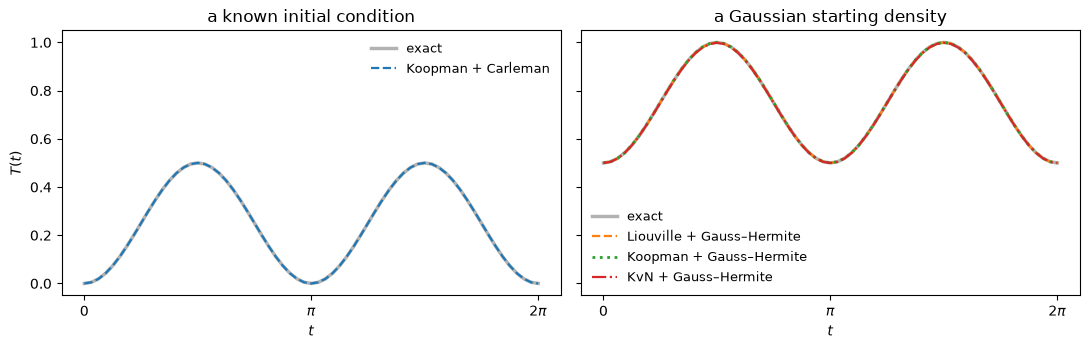

In [7]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)

axes[0].plot(times, exact_point, "k-", lw=2.5, alpha=0.3, label="exact")
axes[0].plot(times, carleman_T, "C0--", lw=1.6, label="Koopman + Carleman")
axes[0].set(title="a known initial condition", xlabel="$t$", ylabel="$T(t)$")

axes[1].plot(times, exact_density, "k-", lw=2.5, alpha=0.3, label="exact")
axes[1].plot(times, liouville_T, "C1--", lw=1.6, label="Liouville + Gauss–Hermite")
axes[1].plot(times, koopman_T, "C2:", lw=2.0, label="Koopman + Gauss–Hermite")
axes[1].plot(times, kvn_T, "C3-.", lw=1.6, label="KvN + Gauss–Hermite")
axes[1].set(title="a Gaussian starting density", xlabel="$t$")

for ax in axes:
    ax.set_xticks([0, np.pi, 2 * np.pi], ["0", r"$\pi$", r"$2\pi$"])
    ax.legend(frameon=False, fontsize=9)
fig.tight_layout()
plt.show()

## Comparison with the closed form

The left panel is the deterministic trajectory: $T$ starts at zero, the oscillator being at rest at
maximum displacement, and peaks at $t=\pi/2$ where all the energy is kinetic.

The right panel sits half a unit higher and never reaches zero: the spread of the density adds
$\tfrac12\operatorname{Var}p=\tfrac12$ to the mean motion.

Three generators and two bases give the same physics. The two that expand $\rho$ agree with the
closed form to $3\times10^{-6}$, and the one that expands $\sqrt\rho$ to $2\times10^{-3}$.


---

[Notebook index](../README.md) · [KPP–Fisher, large grid →](kpp_fisher_1d.ipynb)